# Прогнозирование поведения клиента (ДЗ)

Привет!

В этом домашнем задании тебе предстоит построить кривые def rate, внедрить def rate в NPV-модель и исследовать зависимость обновленной модели от выбранного скора (подробные пункты перечислены ниже).

Для выполнения тебе понадобится выборка с данными, которую использовали на семинаре (**data_vintages.csv**), x_score и PD (**data_scores.csv**). Не бойся выходить за рамки методов, предлженных в лекции.

Главное - не забывай **аргументировать** свой выбор и давать **комментарии** своим действиям. 

Удачи!

#### Как будет оцениваться работа:
За это ДЗ ты можешь получить максимум **10 баллов**. Все пункты весят по-разному, баллы указаны рядом с пунктами. Баллы могут сниматься в случае неполного выполнения задания или отсутствия аргументации.


#### Задачи:

1) Построить кривые DEF rate (5 баллов)
    - Выбрать переменную для разбивки по бакетам (0.5 балла)
    - Провести анализ поколений (0.5 балла)
    - Построить винтажи DEF rate (0.5 балла)
    - Провести анализ на особые точки (0.5 балла)
    - Провести анализ наличия внешних воздействий и при необходимости вычистить кривые (2 балла)
    - Построить среднее по винтажам для каждого бакета (0.5 балла)
    - Сгладить кривые (0.5 балла)
    
2) Внести в модель построенную кривую DEF rate и исследовать зависимость от скора (5 баллов)
    - Реализовать метод для расчета DEF rate по поданному скору (3 балла)
    - Рассчитать NPV для кредита с заданными параметрами (1 балл)
    - Построить кривую зависимости NPV от скора (1 балл)
    
**Пожалйуста, аргументируйте свои решения по каждому пункту**

В качестве результата приложи текущий ноутбук с названием 'Surname_def.ipynb'

## Кривые DEF rate

#### Выгружаем данные с винтажами

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# В качестве данных для винтажей используй файл с семинара data_vintages.csv
df = pd.read_csv("data_vintages.csv", sep=';', index_col=0, parse_dates=["gen_month_dt", "gen_quarter_dt"])
df

,user_id,statement_num,gen_month_dt,gen_quarter_dt,clo_flg,def_flg,dlq_flg,act_flg,prev_clo_flg,prev_def_flg,prev_dlq_flg,prev_act_flg
0,127336,19,2019-07-01,2019-07-01,0,0,0,1,0,0,0,1
1,35907,16,2019-04-01,2019-04-01,1,0,0,0,1,0,0,0
2,45228,21,2019-05-01,2019-04-01,0,0,0,1,0,0,0,1
3,39035,23,2019-07-01,2019-07-01,0,0,0,1,0,0,0,1
4,130780,19,2019-08-01,2019-07-01,1,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
2493263,64006,19,2019-05-01,2019-04-01,1,0,0,0,0,0,1,1
2493264,138666,21,2019-09-01,2019-07-01,1,0,0,0,0,0,0,1
2493265,120568,1,2019-08-01,2019-07-01,0,0,0,1,0,0,0,1
2493266,191861,6,2020-01-01,2020-01-01,0,0,0,1,0,0,0,1


#### Выгружаем данные со скорами для дальнейшей разбивки на бакеты

In [3]:
# Тебе понадобятся два скора: 
# 1) x_score из файла data_scores.csv 
# 2) PD (вероятность дефолта за 12 месяцев), который вы получили в предыдущем ДЗ
df_scores = pd.read_csv("data_scores.csv", sep=';', decimal=',', index_col=0)
df_scores

,user_id,pd,x_score
0,9311,0.035025,0.219980
1,155026,0.046279,0.146986
2,17584,0.007221,0.343298
3,156231,0.069679,0.186684
4,123587,0.010402,0.305582
...,...,...,...
104815,143584,0.016164,0.309760
104816,155700,0.042533,0.397730
104817,190265,0.037467,0.114701
104818,212775,0.037876,0.260569


#### Бъем выборку на бакеты и джойним с данными с винтажами

In [100]:
# Разбей данные на бакеты по каждой переменной (базовый набор бакетов - 3)


df_scores = df_scores.sort_values(["pd"], ignore_index=True)
df_scores["pd_bucket"] = np.minimum(df_scores.index // (df_scores.shape[0] // 3), 2)
print(df_scores.groupby(["pd_bucket"])["pd"].mean())

df_scores = df_scores.sort_values(["x_score"], ignore_index=True)
df_scores["x_bucket"] = np.minimum(df_scores.index // (df_scores.shape[0] // 3), 2)
print(df_scores.groupby(["x_bucket"])["x_score"].mean())

df = df.merge(
    df_scores[["user_id", "pd_bucket", "x_bucket", "pd", "x_score"]],
    how="left",
    on="user_id",
).dropna()


df

pd_bucket
0    0.011040
1    0.032685
2    0.068209
Name: pd, dtype: float64
x_bucket
0    0.133270
1    0.220838
2    0.379452
Name: x_score, dtype: float64


,user_id,statement_num,gen_month_dt,gen_quarter_dt,clo_flg,def_flg,dlq_flg,act_flg,prev_clo_flg,prev_def_flg,prev_dlq_flg,prev_act_flg,pd_bucket,x_bucket,pd,x_score
0,127336,19,2019-07-01,2019-07-01,0,0,0,1,0,0,0,1,1,2,0.021296,0.469410
1,35907,16,2019-04-01,2019-04-01,1,0,0,0,1,0,0,0,2,0,0.064742,0.157215
2,45228,21,2019-05-01,2019-04-01,0,0,0,1,0,0,0,1,0,2,0.018490,0.469583
3,39035,23,2019-07-01,2019-07-01,0,0,0,1,0,0,0,1,1,1,0.025882,0.210896
4,130780,19,2019-08-01,2019-07-01,1,0,0,0,1,0,0,0,1,1,0.024330,0.269492
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493263,64006,19,2019-05-01,2019-04-01,1,0,0,0,0,0,1,1,2,1,0.052035,0.188233
2493264,138666,21,2019-09-01,2019-07-01,1,0,0,0,0,0,0,1,0,1,0.012906,0.221981
2493265,120568,1,2019-08-01,2019-07-01,0,0,0,1,0,0,0,1,2,0,0.059505,0.104274
2493266,191861,6,2020-01-01,2020-01-01,0,0,0,1,0,0,0,1,0,0,0.007966,0.172479


### Выбери переменную, которая делит кривые наилучшим образом (0.5 баллов)

 Из двух скоров (x_score и ваш PD) выбери тот, который разделяет кривые наилучшим образом

Немного видоизменям код из семинара заменной метрики dlq_flg на def_flg

In [4]:
def plot_def_rate_by_bucket(df, bucket):
    return (
        df.groupby([bucket, "statement_num"])
        .agg({"def_flg": np.sum, "user_id": np.count_nonzero})
        .rename(columns={"def_flg": "def_cnt", "user_id": "cnt"})
        # Нормируем на стартовое количество клиентов в бакете в момент выдачи
        .assign(total_cnt=lambda x: x.groupby(bucket)["cnt"].transform("first"))
        .eval("def_rate = def_cnt", inplace=False)
        .unstack(bucket)["def_rate"]
        .plot(figsize=(10, 6), grid=True, lw=3)
    )

In [5]:
# График по pd_bucket
plot_def_rate_by_bucket(df, "pd_bucket")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize="14")
plt.title("Кривая def_rate по pd_bucket", size=18, verticalalignment="bottom")
plt.xlabel("Месяц жизни клиента", size=14)
plt.ylabel("def_rate", size=14)
plt.tick_params(axis="both", which="major", labelsize=12)
plt.show()


# График по x_bucket
plot_def_rate_by_bucket(df, "x_bucket")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize="14")
plt.title("Кривая def_rate по x_bucket", size=18, verticalalignment="bottom")
plt.xlabel("Месяц жизни клиента", size=14)
plt.ylabel("def_rate", size=14)
plt.tick_params(axis="both", which="major", labelsize=12)
plt.show()

KeyError: 'pd_bucket'

#### Вывод: здесь укажи выбранную тобой переменную и обоснуй свой выбор

Расстояние между графиками PD больше чем на графиках x_score, даже без учета разности масштаба по оси Y. Одназначно берем pd


### Анализ поколений (0.5 баллов)

Отрисуй распределение данных во времени в разбивке по выбранной перменной

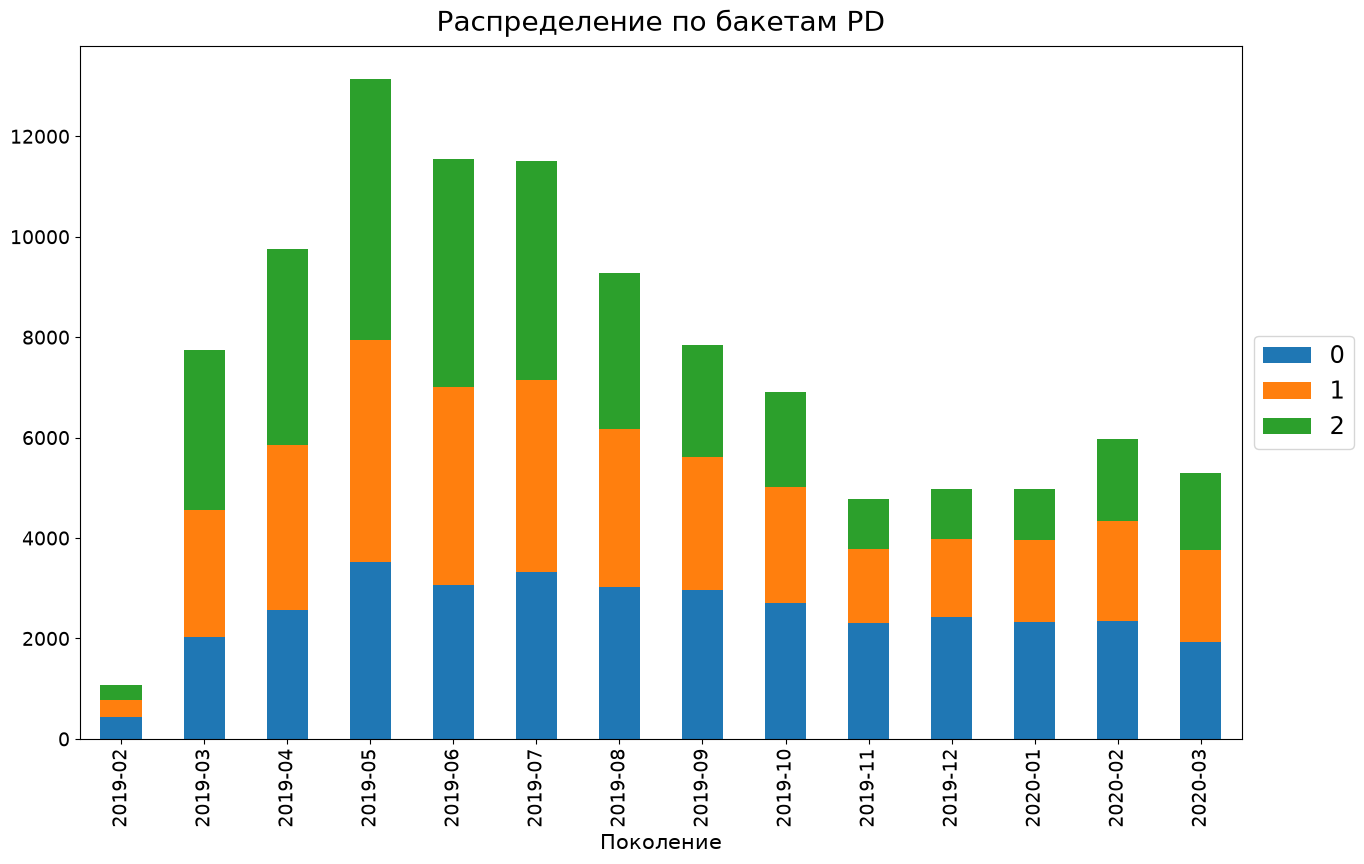

In [103]:
def plot_distribution(df, bucket):
    # Установить gen_month_dt как индекс
    df = df.set_index("gen_month_dt").copy()

    # Теперь индекс — это DatetimeIndex, можно установить частоту
    df.index = df.index.to_period(freq="M")  # 'M' — ежемесячные данные

    return pd.pivot_table(
        df,
        index=[bucket],
        columns="gen_month_dt",  # делаем сводную таблицу и транспонируем ее
        values="user_id",
        aggfunc=pd.Series.nunique,
        fill_value=0,
    ).T.plot(
        kind="bar", stacked=True, figsize=(15, 9)
    )  # Рисуем график распределения столбиками


plot_distribution(df, "pd_bucket")

plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize="17")
plt.title("Распределение по бакетам PD", size=20, verticalalignment="bottom")
plt.xlabel("Поколение", size=15)
plt.tick_params(axis="both", which="major", labelsize=14)

Немного поменял функцию с семинара для того чтобы показывать именно количество людей, а не строчек.

#### Вывод: сделай выводы по полученным графикам. Нужно ли исключать какие-то бакеты/поколения? Если да, то реализуй их исключение из выборки

Нужно исключить поколение 2019-02, из-за малого числа наблюдений, дальшейший график будет слишком шумный. В остальном же думаю стоит отставить как есть,хоть и есть дизбаланс в бакетах с 2019-11 по 2020-01.

In [104]:
df = df.loc[df["gen_month_dt"] != "2019-02-01"]

### Кривые DEF Rate в разбивке по бакетам (0.5 баллов)

Реализуй функцию, которая отрисовывает винтажи DEF rate в разбивке по бакетам

In [105]:
def plot_def_rate_by_generation(data, pd_bucket):
  # фильтруем данные по бакету и агрегируем дефолты и кол-во клиентов
  df_bucket = (
      data.query("pd_bucket == @pd_bucket")
      .groupby(["gen_month_dt", "statement_num"])
      .agg({"def_flg": np.sum, "user_id": np.count_nonzero})
      .rename(columns={"def_flg": "def_cnt", "user_id": "cnt"})
  )

  # находим начальный размер каждого поколения
  # и рассчитываем кумулятивный def_rate
  df_bucket = (
      df_bucket.assign(
          total_cohort_cnt=lambda x: x.groupby("gen_month_dt")[
              "cnt"
          ].transform("first")
      )
      .eval("def_rate = def_cnt / total_cohort_cnt", inplace=False)
      .unstack("gen_month_dt")["def_rate"]
  )

  # отрисовка графика
  df_bucket.plot(figsize=(15, 8), grid=True, lw=2.5)

  plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize="17")

  plt.title(
      "Кривая def_rate, pd_bucket = " + str(pd_bucket),
      size=18,
      verticalalignment="bottom",
  )
  plt.xlabel("Месяц жизни клиента", size=15)
  plt.ylabel("DEF rate", size=14)
  plt.tick_params(axis="both", which="major", labelsize=14)
  plt.show()

C:\Users\Honor Pro\AppData\Local\Temp\ipykernel_1676\3116426171.py:6: FutureWarning: The provided callable <function sum at 0x000002482EAA6480> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  .agg({"def_flg": np.sum, "user_id": np.count_nonzero})


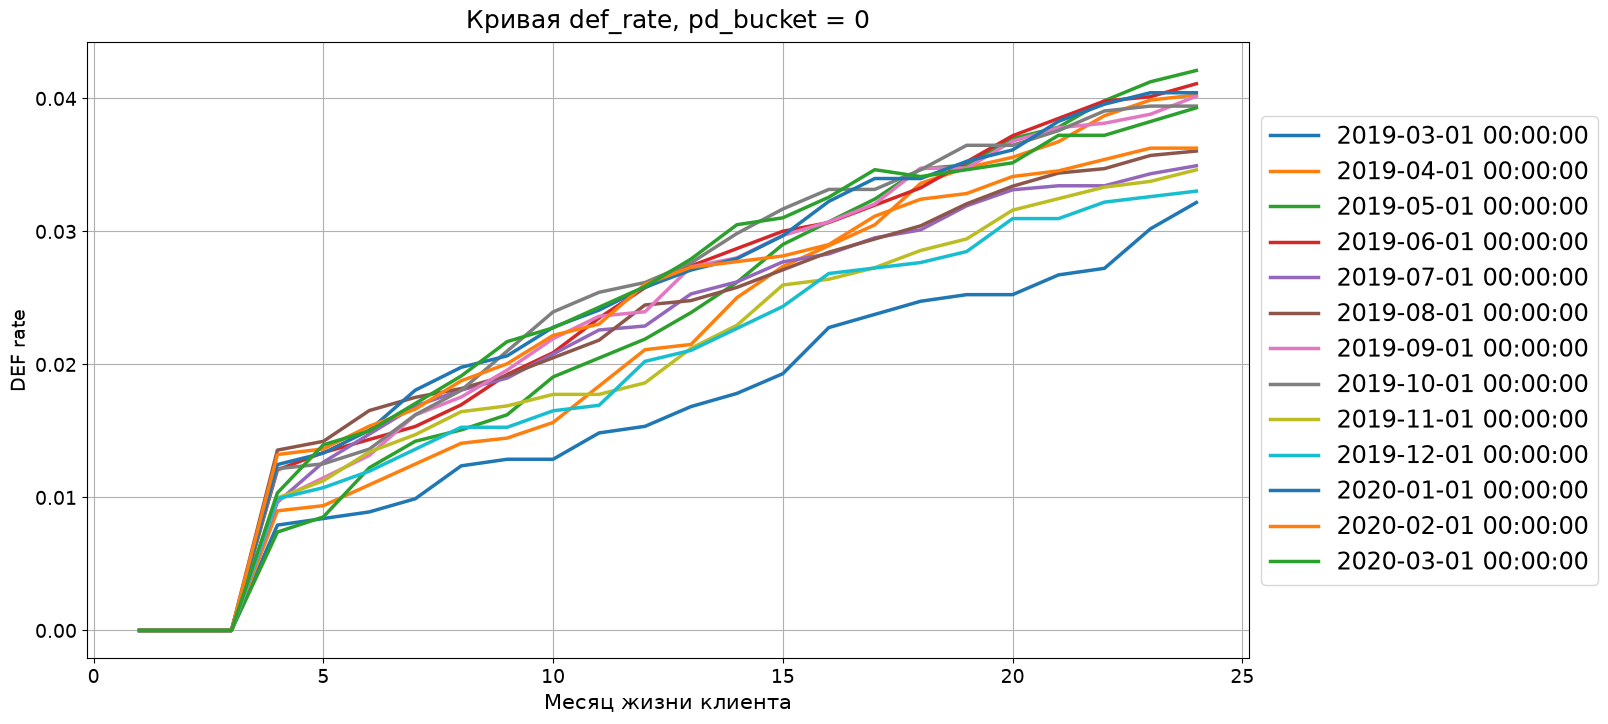

C:\Users\Honor Pro\AppData\Local\Temp\ipykernel_1676\3116426171.py:6: FutureWarning: The provided callable <function sum at 0x000002482EAA6480> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  .agg({"def_flg": np.sum, "user_id": np.count_nonzero})


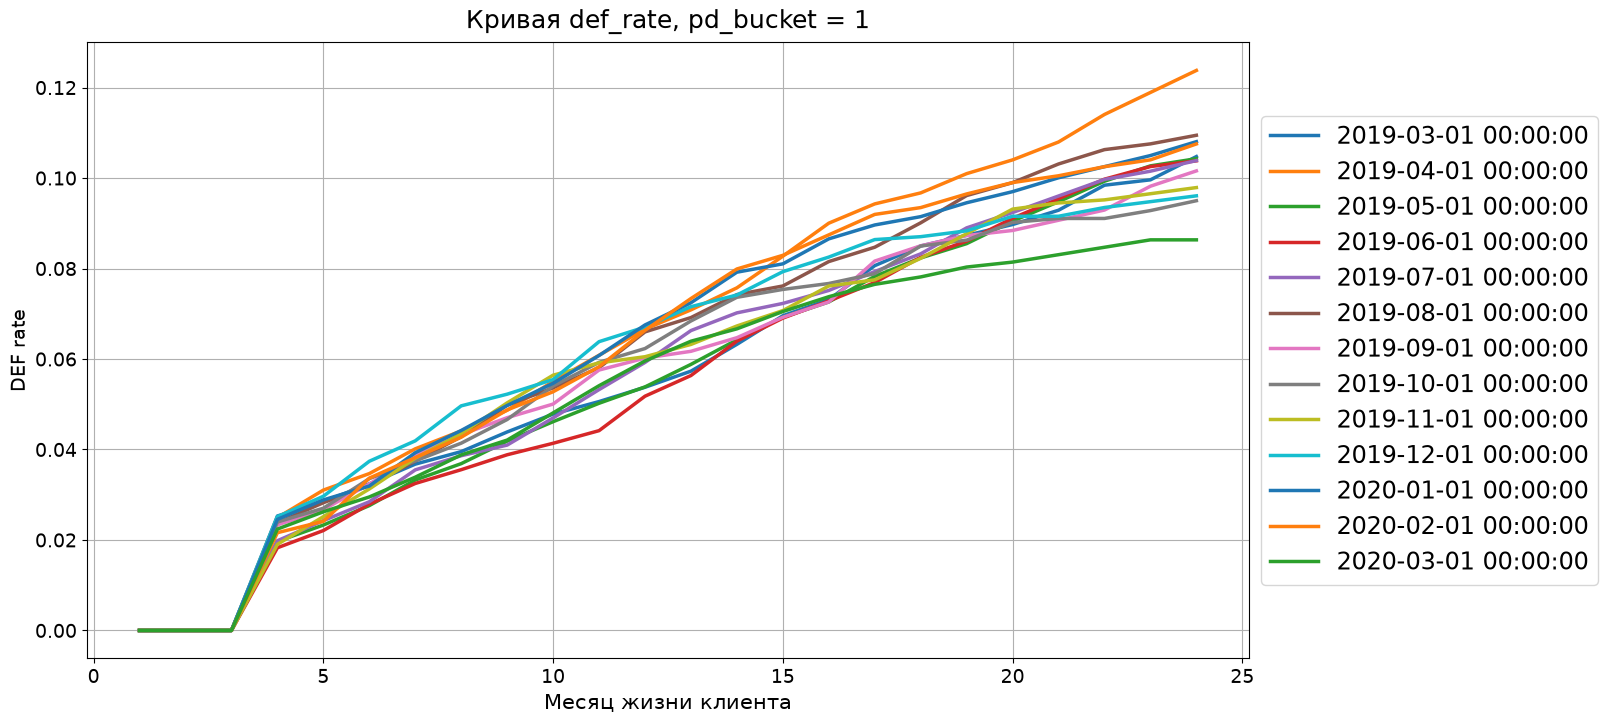

C:\Users\Honor Pro\AppData\Local\Temp\ipykernel_1676\3116426171.py:6: FutureWarning: The provided callable <function sum at 0x000002482EAA6480> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  .agg({"def_flg": np.sum, "user_id": np.count_nonzero})


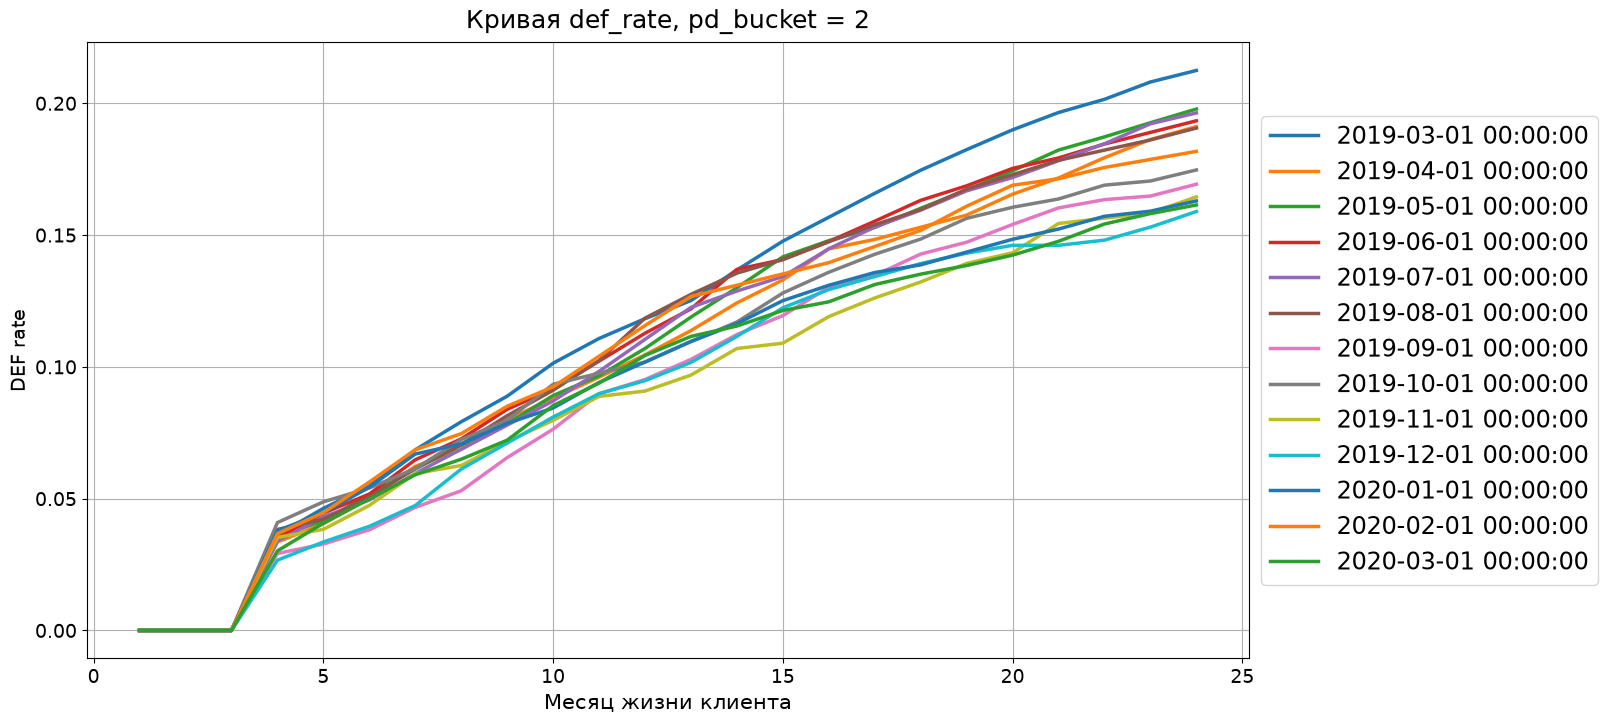

In [106]:
buckets = sorted(df["pd_bucket"].unique())

for bucket in buckets:
  plot_def_rate_by_generation(df, bucket)

#### Выводы: сделай выводы по полученным графикам

Что pd хорошо ранжирует заемщиков, мы видим, что от бакета к бакету увелчивается def rate. Общая тендениця в каждом бакете идет довольно плотно, за исключением некторых случаев (например аномально низкий def rate в нулевом бакете у 2020-01 или же в первом отклонения оранжевой кривой).

### Особые точки (0.5 баллов) 
#### Есть ли в винтажах особые точки? Укажи их. Какова их природа? Нужно ли их исключать?

Ну особыми можно назвать первые 4 точки. Первые 3 когда rate равен 0, природа из заключается в том что дефолт начинается с 4 месяца просрочки и чисто никак нельзя получить дефолт за меньшее количество месяцев. И точка 4 когда как раз таки происходит скачок резкий, когда получают первые дефолты.
Исключать их разумеется не нужно, это базовое свойство нашей метрики.

### Макроэкономические воздействие (2 балла)

#### Есть ли в винтажах DEF rate макроэкономическое воздействие (нарисуй график иллюстрирующее это воздействие)? Если да, то предположи какое событие его вызвало и почему?
#### В случае наличия внешнего влияния 
#### 1) Разложи кривые на внешнее воздействие и созревание кривых
#### 2) Отрисуй график внешнего воздествия
#### 3) Отрисуй вычищенные винтажи DEF rate в разбивке по бакетам
#### 4) Посчитай среднее для этих бакетов и реализуй сглаживание

In [ ]:
#Базовые функции декомпозиции с семинара
def curve_build(data, feature, generation="gen_month_dt",
                statement_num="statement_num", group_label="1", stable_from=6):

    df_query = data.sort_values([generation, statement_num]).reset_index(drop=True)
    generation_min = df_query[generation].min()

    values = df_query[feature].to_numpy(dtype=float)
    st_nums = (df_query[statement_num].to_numpy(dtype=int) - 1)

   # календарный индекс t=0..T-1 для каждой строки
    dates = (
        df_query[generation].dt.year * 12 + df_query[generation].dt.month
        - (generation_min.year * 12 + generation_min.month)
        + df_query[statement_num].to_numpy(dtype=int) - 1
    ).to_numpy(dtype=int)

    A = int(st_nums.max() + 1)          # длина M(a)
    T = int(dates.max() + 1)            # длина E(t)

    stable_mask = (np.arange(T) >= stable_from)

    def unpack_x(x):
        E_raw = x[:T]
        M_raw = x[T:T+A]

        # среднее только по "стабильному" окну  
        if stable_mask.any():
            mean_E = E_raw[stable_mask].mean()
        else:
            mean_E = E_raw.mean()

        if mean_E == 0:
            mean_E = 1e-12

        # теперь mean(E[stable_mask]) == 1
        E = E_raw / mean_E

        # сохраняем инвариантность произведения E*M
        M = M_raw * mean_E
        return E, M

    def r_square(x):
        E, M = unpack_x(x)
        pred = E[dates] * M[st_nums]
        return np.sum((values - pred) ** 2)

    x0 = np.ones(T + A, dtype=float)

    res0 = minimize(
        r_square,
        x0,
        tol=1e-6,
        method="Powell",
        options={"disp": False, "maxiter": 1000},
    )

    E_hat, M_hat = unpack_x(res0.x)

    external_data = pd.DataFrame({
        "month_dt": [generation_min + pd.DateOffset(months=i) for i in range(T)],
        group_label: E_hat
    })

    maturation_data = pd.DataFrame({
        "statement_num": np.arange(1, A + 1),
        group_label: M_hat
    })

    # fitted: D / E (если хотите "очистить" от макро)
    df_query = df_query.copy()
    df_query["month_dt"] = pd.to_datetime(df_query["month_dt"], errors="coerce")
    external_data["month_dt"] = pd.to_datetime(external_data["month_dt"], errors="coerce")

    df_fitted = df_query.merge(external_data, on="month_dt", how="left")
    df_fitted["fitted_feature"] = df_fitted[feature] / df_fitted[group_label]

    return {
        "res0": res0,
        "external_data": external_data,
        "maturation_data": maturation_data,
        "df_fitted": df_fitted,
    }


def decomposition(
    df,
    generation="gen_month_dt",
    group="pd_bucket",
    statement_num="statement_num",
    feature="def_rate",
    optimization_query="",
):
    """Винтажи исследуемой переменной по календарному времени
    
        **Аргументы**
        df : pandas.DataFrame
            таблица с данными
        generation : datetime
            название поля с поколениями
        group : str
            название поля с бакетами
        statement_num : int
            название поля с номером выписки
        feature: str
            название поля с исследуемой переменной
        optimization_query: str
            ограничение выборки для оптимизации
        **Результат**
        dictionary : dict
        """
    
    #разбираемся со случаем пустых аргументов

    if optimization_query == "":
        df_query = pd.DataFrame(df)
    else:
        df_query = df.query(optimization_query)

    timedelta = df_query[statement_num].apply(lambda x: pd.DateOffset(months=x - 1))
    df_query["month_dt"] = df_query[generation] + timedelta

    df_query.sort_values(by=[group], inplace=True)
    groups = pd.Series(df_query[group].drop_duplicates())

    i = 0
    for g in groups:
        df_temp = df_query[df_query[group] == g]
        print(f"Оптимизация для {group} = {g}")

        res = curve_build(
            df_temp,
            feature=feature,
            generation=generation,
            statement_num=statement_num,
            group_label=str(g),
        )
        df_fitted_temp = pd.DataFrame(res["df_fitted"])
        df_fitted_temp[group] = g

        if i == 0:
            external_data = pd.DataFrame(res["external_data"])[["month_dt", str(g)]]
            maturation_data = pd.DataFrame(res["maturation_data"])[[statement_num, str(g)]]
            df_fitted = pd.DataFrame(df_fitted_temp)
        else:
            external_data = external_data.merge(right=res["external_data"], on=["month_dt"])
            maturation_data = maturation_data.merge(right=res["maturation_data"], on=[statement_num])
            df_fitted = pd.concat([df_fitted, df_fitted_temp])
        i += 1

    return {
        "external_data": external_data,
        "maturation_data": maturation_data,
        "fitted_data": df_fitted,
    }

In [108]:
# расчет DEF rate
df_def_ratio = (
    df.groupby(["pd_bucket", "gen_month_dt", "statement_num"], as_index=False)
    .agg({"def_flg": np.sum, "user_id": np.count_nonzero})
    .rename(columns={"def_flg": "def_cnt", "user_id": "cnt"})
    .assign(total_cohort_cnt=lambda x: x.groupby(["pd_bucket", "gen_month_dt"])["cnt"].transform("first"))
    .eval("def_rate = def_cnt / total_cohort_cnt", inplace=False)
)

# вызов декомпозиции
res = decomposition(
    df_def_ratio,
    generation="gen_month_dt",
    group="pd_bucket",
    statement_num="statement_num",
    feature="def_rate",
)

C:\Users\Honor Pro\AppData\Local\Temp\ipykernel_1676\1106872398.py:4: FutureWarning: The provided callable <function sum at 0x000002482EAA6480> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  .agg({"def_flg": np.sum, "user_id": np.count_nonzero})
C:\Users\Honor Pro\AppData\Local\Temp\ipykernel_1676\2381620881.py:121: PerformanceWarning: Adding/subtracting object-dtype array to DatetimeArray not vectorized.
  df_query["month_dt"] = df_query[generation] + timedelta


Оптимизация для pd_bucket = 0
Оптимизация для pd_bucket = 1
Оптимизация для pd_bucket = 2


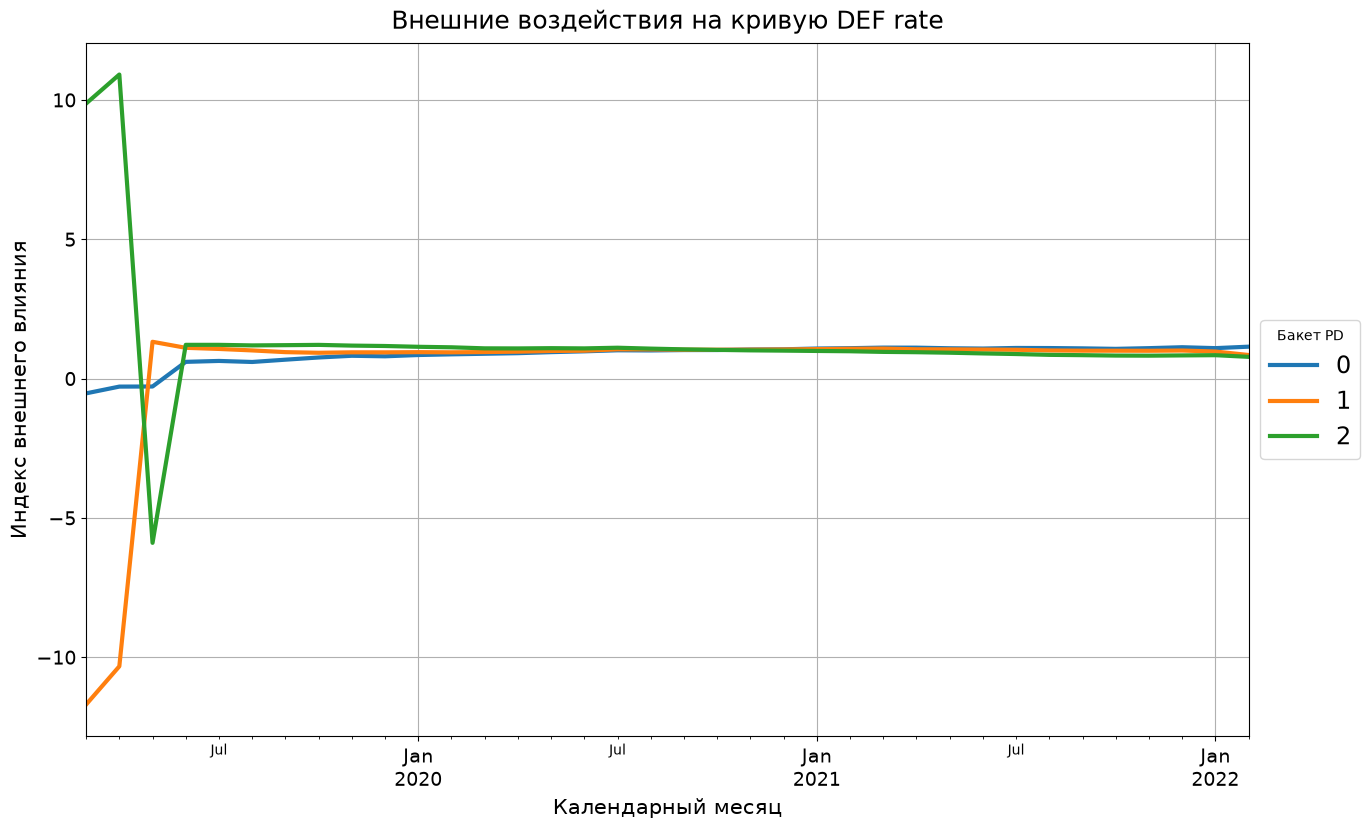

In [109]:
# График макроэкономического воздействия
res["external_data"].set_index("month_dt").plot(figsize=(15, 9), grid=True, lw=3)

plt.legend(title="Бакет PD", loc="center left", bbox_to_anchor=(1, 0.5), fontsize="17")
plt.title("Внешние воздействия на кривую DEF rate", size=18, verticalalignment="bottom")
plt.xlabel("Календарный месяц", size=15)
plt.ylabel("Индекс внешнего влияния", size=15)
plt.tick_params(axis="both", which="major", labelsize=14)
plt.show()

Наблюдается стабильность кроме начального этапа. Первые 3 месяца жизни кредита дефолты физически равны 0, отсюда и такой эффект.
Так такого макроэкономического эффекта не наблюдается.

### Среднее по бакетам (0.5 баллов) 
Выбери один из способой нахождение средней кривой (возможные способы указаны в лекции). Обоснуй свой выбор.

Реализуй функцию построения среднего.

Усреднение кривых созревания после очистки

Если взять обычное среднее, оно впитает случайные внешнее воздействие. Но в нашем случае это бы не сильно сказалось

C:\Users\Honor Pro\AppData\Local\Temp\ipykernel_1676\3656445774.py:5: FutureWarning: The provided callable <function mean at 0x000002482EAA7880> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  .agg({"fitted_feature": np.mean})
C:\Users\Honor Pro\AppData\Local\Temp\ipykernel_1676\3656445774.py:17: FutureWarning: The provided callable <function mean at 0x000002482EAA7880> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  .agg({"fitted_feature": np.mean})


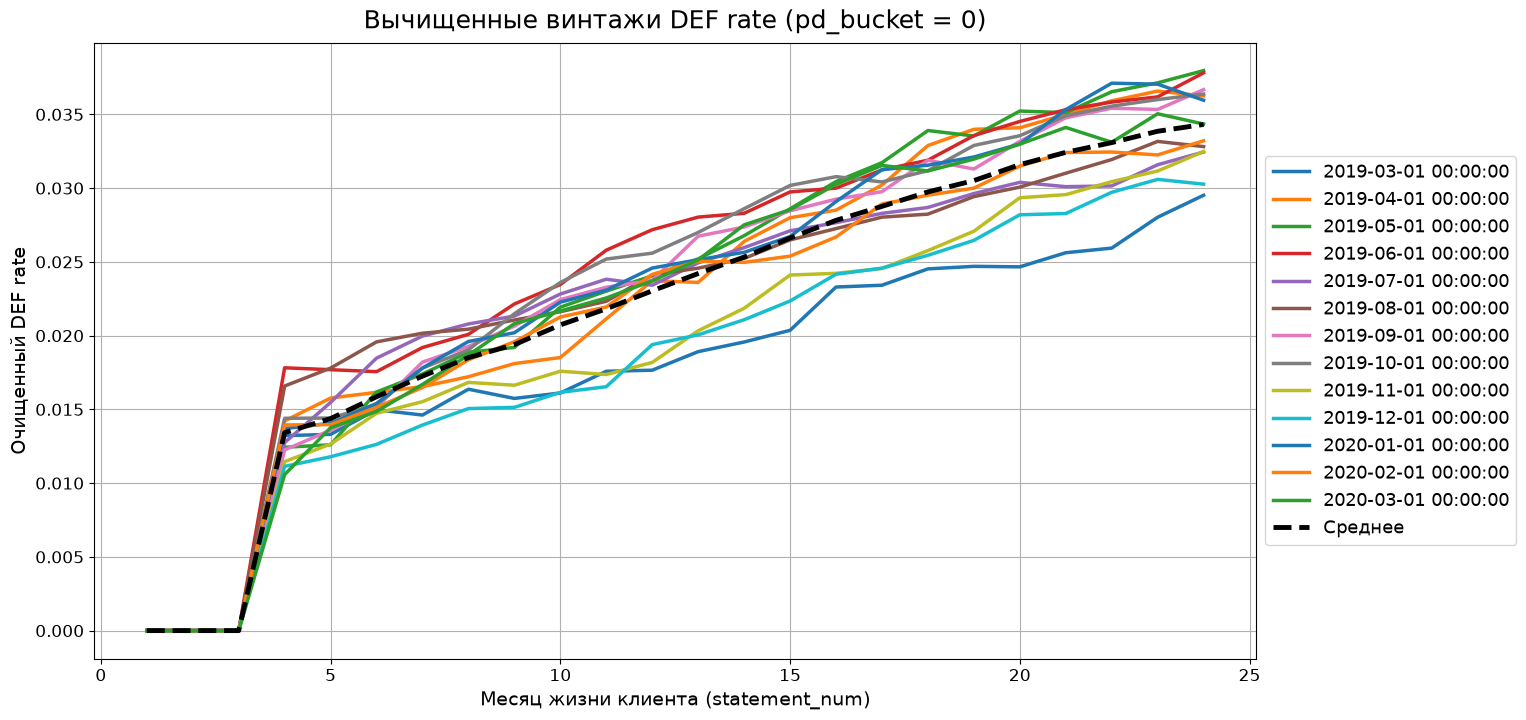

C:\Users\Honor Pro\AppData\Local\Temp\ipykernel_1676\3656445774.py:17: FutureWarning: The provided callable <function mean at 0x000002482EAA7880> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  .agg({"fitted_feature": np.mean})


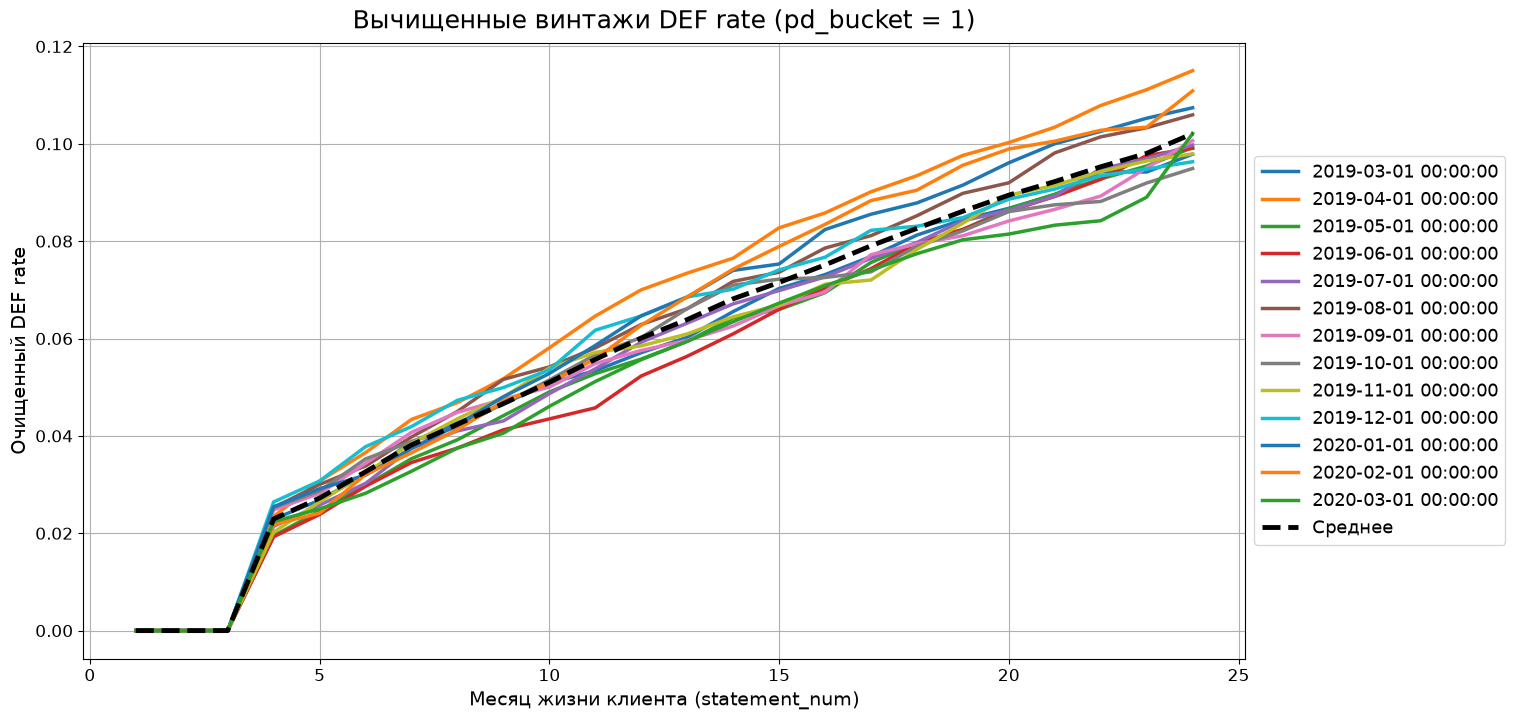

C:\Users\Honor Pro\AppData\Local\Temp\ipykernel_1676\3656445774.py:17: FutureWarning: The provided callable <function mean at 0x000002482EAA7880> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  .agg({"fitted_feature": np.mean})


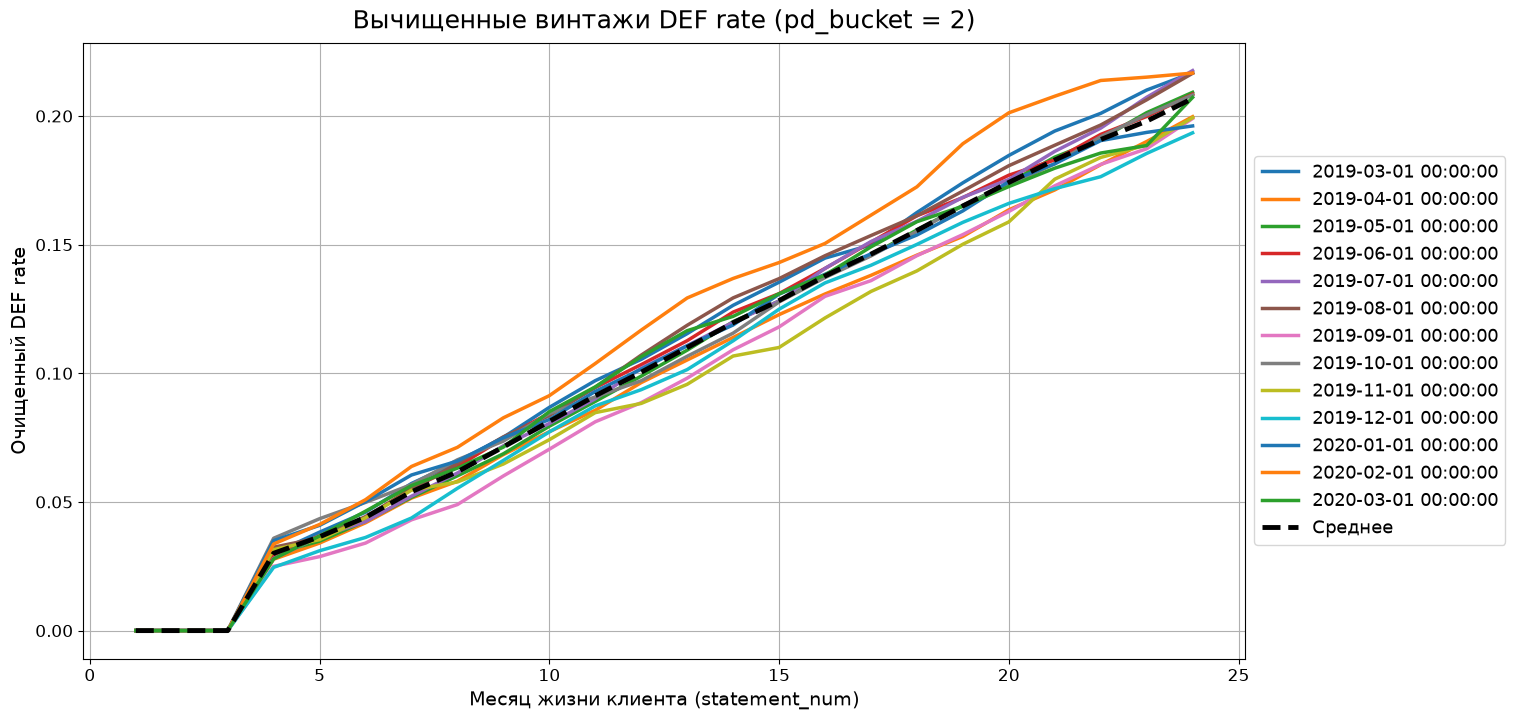

In [110]:
# расчет среднего вычищенного профиля
def_rate_mean = (
    res["fitted_data"]
    .groupby(["pd_bucket", "statement_num"])
    .agg({"fitted_feature": np.mean})
    .rename(columns={"fitted_feature": "Среднее"})
)

buckets = sorted(df["pd_bucket"].unique())

def plot_def_rate_mean(pd_bucket):
    # винтажи
    (
        res["fitted_data"]
        .query(f"pd_bucket == {pd_bucket}")
        .groupby(["gen_month_dt", "statement_num"])
        .agg({"fitted_feature": np.mean})
        .unstack("gen_month_dt")["fitted_feature"]
        .plot(figsize=(15, 8), grid=True, lw=2.5)
    )

    # средняя очищенная кривая
    def_rate_mean.loc[pd_bucket, "Среднее"].plot(
        figsize=(15, 8), grid=True, lw=3.5, color="Black", ls="dashed", label="Среднее"
    )

    plt.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize="13")
    plt.title(f"Вычищенные винтажи DEF rate (pd_bucket = {pd_bucket})", size=18, verticalalignment="bottom")
    plt.xlabel("Месяц жизни клиента (statement_num)", size=14)
    plt.ylabel("Очищенный DEF rate", size=14)
    plt.tick_params(axis="both", which="major", labelsize=12)
    plt.show()

for b in buckets:
    plot_def_rate_mean(b)

### Сглаживание средних кривых (0.5 баллов) 

Рассмотри несколько функций для сглаживания кривой (можешь взять готовые из семинара, либо реализовать свои).

In [111]:
# Функции сглаживания
def approximation(df, start=4, finish=24, degree=2):
    df_res = pd.DataFrame(df)
    df_res["Полином"] = df["Среднее"]
    linear_coeff = np.polyfit(
        np.arange(start, finish + 1), df.loc[start:finish, "Среднее"], degree
    )
    linear_coeff = np.poly1d(linear_coeff)
    df_res.loc[start:finish, "Полином"] = linear_coeff(np.arange(start, finish + 1))
    df_res.loc[finish + 1 :, "Полином"] = linear_coeff(finish + 1)
    return df_res

#### Вывод: укажи выбранную функцию и обоснуй свой выбор. Были ли точки, к которым не применил(-a) сглаживание? Почему?

Полиномиальная аппроксимация 2 степени, крутой прирост вначале а потом стабильный рост полином вроде неплохо ложиться.

Первые 3 месяца жизни кредита так как там 0


### Отрисуй сглаженные кривые по всем трем бакетам PD

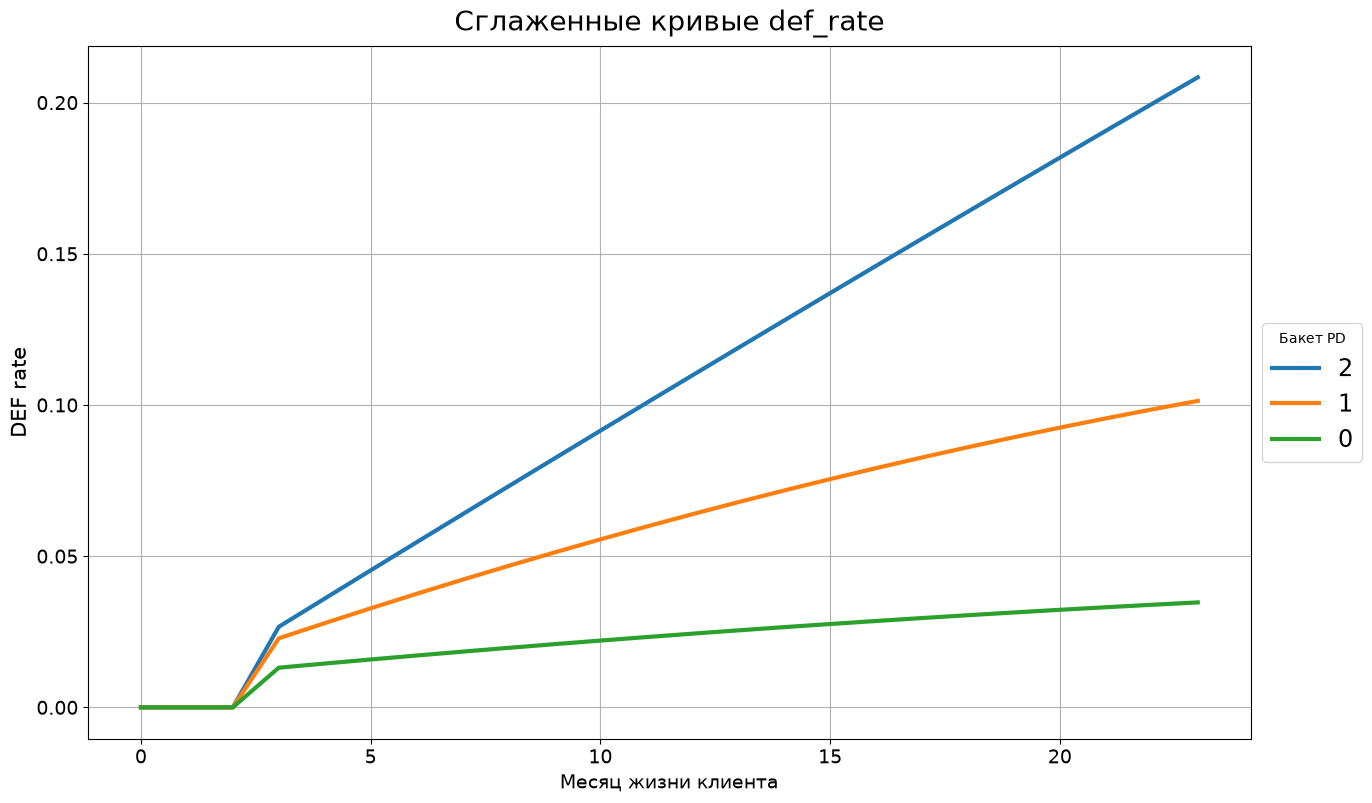

In [112]:
# Запоминаем набор бакетов и заводим пустой датафрейм под результат
df_smooth_result = pd.DataFrame()


# Далем полиномиальное сглаживание для каждого бакета
for bucket in sorted(buckets, reverse=True):
    df_temp = (
        def_rate_mean.query(f"pd_bucket == {bucket}")
        .reset_index()
        .set_index(["statement_num"])
    )
    poly_df = approximation(df_temp, start=4, finish=24, degree=2)
    
    poly_vals = np.where(poly_df.index <= 3, 0.0, poly_df["Полином"])
    poly_vals = np.maximum.accumulate(poly_vals)
    
    df_smooth_result[str(bucket)] = poly_vals


# Строим итоговый график
df_smooth_result.plot(figsize=(15, 9), grid=True, lw=3)
plt.legend(title="Бакет PD", loc="center left", bbox_to_anchor=(1, 0.5), fontsize="17")
plt.title("Сглаженные кривые def_rate", size=20, verticalalignment="bottom")
plt.xlabel("Месяц жизни клиента", size=14)
plt.ylabel("DEF rate", size=15)
plt.tick_params(axis="both", which="major", labelsize=14)
plt.show()

# Внедрение в NPV-модель

## Добавь в NPV-модель метод с расчетом DEF rate по твоей кривой

In [113]:
import numpy as np

class NPVModel:

    #добавим параметров для 3 задания
    insurance_share_limit = 0.005
    insurance_share_cur = 0.40
    insurance_share_dlq = 0.60
    insurance_event_prob = 0.001

    avg_missed_payments = 1.5
    recovery = 0.50
    dlq_penalty_amount = 500
    oper_costs = 100
    collection_costs = 600
    tax_rate = 0.25
    discounting_rate = 0.30
    eq_req = 0.125
    cost_of_funds = 0.16
    acquisition_cost = 1000

    def __init__(self):
        pass

    def model_balance_calculations(self, amount, rate, term):
        '''
        Расчет модельных баланса, выплаченных процентов, регулярного платежа
        :param amount: Сумма кредита
        :param rate: Ставка
        :param term: Срок
        :return:
        balance : np.array(101) : остаток тела долга по кредиту на каждый месяц
        interest : np.array(101) : выплата по процентам каждый месяц
        regular_payment : float : размер регулярного платежа
        '''

        regular_payment = round(amount * (rate / 12) *\
                                (1 + (rate / 12)) / (1 - ((1 + rate / 12) ** (-term))))
        # График баланса и процентов
        balance = np.zeros(101)
        interest = np.zeros(101)
        balance[0] = amount

        for i in range(1, term + 1):
            int_payment = balance[i - 1] * rate / 12
            debt_payment = regular_payment - int_payment
            balance[i] = max(0, round(balance[i - 1] - debt_payment))
            interest[i] = int_payment
        return balance, interest, regular_payment

    def distribution_calc(self, portfolio_distribution, pd=None, pa=None):
        '''
        Расчет распределения по статусам
        :param portfolio_distribution: график распределения по статусам
        :return:
        cur_dist : np.array(101) : доля клиентов в статусе CUR на каждый месяц
        dlq_dist : np.array(101) : доля клиентов в статусе DLQ на каждый месяц
        act_dist : np.array(101) : доля клиентов в статусе ACT на каждый месяц
        def_dist : np.array(101) : доля клиентов в статусе DEF на каждый месяц
        clo_dist : np.array(101) : доля клиентов в статусе CLO на каждый месяц
        '''
        
        cur_dist = portfolio_distribution['CUR']
        dlq_dist = portfolio_distribution['DLQ']
        act_dist = cur_dist + dlq_dist
        def_dist = portfolio_distribution['DEF'] 
        clo_dist = portfolio_distribution['CLO']


        return cur_dist, dlq_dist, act_dist, def_dist, clo_dist

    def cur_balance_calc(self, model_balance, cur_dist):
        '''
        Расчет модельного баланса в статусе CUR
        :param model_balance: плановый график баланса
        :param cur_dist: доля клиентов в статусе CUR на каждый месяц
        :return:
        principal_balance_cur : np.array(101) : principal balance в статусе CUR
        gross_balance_cur : np.array(101) : gross balance в статусе CUR
        '''
        principal_balance_cur = model_balance*cur_dist
        gross_balance_cur = model_balance*cur_dist
        return principal_balance_cur, gross_balance_cur

    def dlq_balance_calc(self, model_balance, regular_payment, dlq_dist):
        '''
        Расчет модельного баланса в статусе DLQ
        :param model_balance: плановый график баланса
        :param regular_payment: размер регулярного платежа
        :param dlq_dist: доля клиентов в статусе DLQ на каждый месяц
        :return:
        principal_balance_dlq : np.array(101) : principal balance в статусе DLQ
        gross_balance_dlq : np.array(101) : gross balance в статусе DLQ
        '''
        principal_balance_dlq = np.append(0, model_balance[:-1])*dlq_dist
        gross_balance_dlq = (model_balance + regular_payment*self.avg_missed_payments)*dlq_dist
        return principal_balance_dlq, gross_balance_dlq

    def act_balance_calc(self, principal_balance_cur, principal_balance_dlq, gross_balance_cur, gross_balance_dlq):
        '''
        Расчет модельного баланса в статусе ACT
        :param principal_balance_cur: principal balance в статусе CUR
        :param principal_balance_dlq: principal balance в статусе DLQ
        :param gross_balance_cur: principal balance в статусе CUR
        :param gross_balance_dlq: principal balance в статусе DLQ
        :param dlq_dist: доля клиентов в статусе DLQ на каждый месяц
        :return:
        principal_balance_act : np.array(101) : principal balance в статусе ACT
        gross_balance_act : np.array(101) : gross balance в статусе ACT
        '''
        principal_balance_act = principal_balance_cur + principal_balance_dlq
        gross_balance_act = gross_balance_cur + gross_balance_dlq
        return principal_balance_act, gross_balance_act

    def def_balance_calc(self, model_balance, regular_payment, def_dist):
        '''
        Расчет модельного баланса в статусе DEF
        :param model_balance: плановый график баланса
        :param regular_payment: размер регулярного платежа
        :param def_dist: доля клиентов в статусе DEF на каждый месяц
        :return:
        principal_balance_def : np.array(101) : principal balance в статусе DEF
        gross_balance_def : np.array(101) : gross balance в статусе DEF
        '''
        principal_balance_def = np.zeros(101)
        gross_balance_def = np.zeros(101)

        def_dist_change = def_dist[4:] - def_dist[3:-1]
        principal_balance_def[4:] = np.cumsum(model_balance[:-4] * def_dist_change)
        gross_balance_def[4:] = np.cumsum((model_balance[4:] + 4 * regular_payment) * def_dist_change)

        return principal_balance_def, gross_balance_def

    def profit_calc(self, principal_balance_act, principal_balance_def, term, rate, dlq_dist):
        '''

        :param principal_balance_act: principal balance в статусе ACT
        :param principal_balance_def: principal balance в статусе DEF
        :param term: срок кредита
        :param rate: тавка по кредиту
        :param dlq_dist: доля клиентов в статусе DLQ на каждый месяц
        :return:
        profit : np.array(101) : доход на каждый месяц
        '''
        interest_profit = principal_balance_act*rate/12
        penatly_profit = dlq_dist*self.dlq_penalty_amount

        new_def_balance = np.append(principal_balance_def[1:], 0) - principal_balance_def
        recovery_profit = new_def_balance*self.recovery

        profit = interest_profit + recovery_profit + penatly_profit
        profit[term+1:] = 0

        return profit

    def loss_calc(self, gross_balance_act, principal_balance_def, term, act_dist, dlq_dist, def_dist):
        '''

        :param gross_balance_act: gross balance в статусе ACT
        :param principal_balance_def: principal balance в статусе DEF
        :param term: срок кредита
        :param act_dist: доля клиентов в статусе ACT на каждый месяц
        :param dlq_dist: доля клиентов в статусе DLQ на каждый месяц
        :param def_dist: доля клиентов в статусе DEF на каждый месяц
        :return:
        loss : np.array(101) : лосс на каждый месяц
        '''
        oper_loss = np.append(act_dist[1:], 0)*self.oper_costs
        loan_loss =  principal_balance_def - np.append(0, principal_balance_def[:-1])
        collection_loss = (np.append(dlq_dist[1:], 0) + np.append(def_dist[1:], 0))*self.collection_costs

        prev_gross_balance_act = np.append(0, gross_balance_act[:-1])
        cost_of_funds_loss = prev_gross_balance_act*(1 - self.eq_req)*self.cost_of_funds/12

        loss = loan_loss + cost_of_funds_loss + oper_loss + collection_loss
        loss[term+1:] = 0

        return loss, loan_loss, cost_of_funds_loss, oper_loss, collection_loss

    def assets_liabilities_calc(self, gross_balance_act):
        '''

        :param gross_balance_act: gross balance в статусе ACT
        :return:
        assets : np.array(101) : активы в проекте
        eq_req_curve : np.array(101) : активы, обеспеченные капиталом
        fund_req_curve : np.array(101) : активы, обеспеченные фондами
        '''

        # assets
        assets = gross_balance_act

        #liabilities
        eq_req_curve = assets*self.eq_req
        fund_req_curve = assets*(1 - self.eq_req)

        return assets, eq_req_curve, fund_req_curve

    def niat_calc(self, profit, loss):
        '''
        Расчет NIAT
        :param profit: суммарный доход на каждый месяц
        :param loss: суммарный лосс на каждый месяц
        :return:
        nibt : np.array(101) : прибыль до налогообложения
        niat : np.array(101) : прибыль после налогообложения
        tax : np.array(101) : налог в каждом месяце
        '''

        nibt = profit - loss
        tax = nibt*self.tax_rate
        niat = nibt - tax

        return nibt, niat, tax

    def cashflow_calc(self, principal_balance_act, principal_balance_def, amount, profit,
                      cost_of_funds_loss, oper_costs, collection_costs, tax, niat, eq_req_curve, fund_req_curve):
        '''
        Расчет денежных потоков
        :param principal_balance_act: principal balance в статусе DEF
        :param principal_balance_def: principal balance в статусе DEF
        :param amount: срок кредита
        :param profit: доход на каждый месяц
        :param cost_of_funds_loss: лоссы на фондирование
        :param oper_costs: операционные расходы
        :param collection_costs: расходы на коллекшн
        :param tax: налог в каждом месяце
        :param niat: доход после налогообложения
        :param eq_req_curve: активы, обеспеченные капиталом
        :param fund_req_curve: активы, обеспеченные фондами
        :return:
        cf_to_client : np.array(101) : денежный поток к клиенту
        cf_to_shareholders : np.array(101) : денежный поток к акционерам
        cf_to_debtholders : np.array(101) : денежный поток к фондам
        cf_to_cost_and_tax : np.array(101) : денежный поток на косты и налоги
        '''
        # client
        delta_principal_balance_act = (np.append(0, principal_balance_act[:100]) - principal_balance_act)
        delta_principal_balance_def = (np.append(0, principal_balance_def[:100]) - principal_balance_def)
        repayments = delta_principal_balance_act - delta_principal_balance_def + profit
        cf_to_client = np.append(amount, -repayments[1:])

        # debtoholder
        fund_req_ch = fund_req_curve - np.append(fund_req_curve[0], fund_req_curve[:-1])
        fund_req_change = np.append(fund_req_curve[0], fund_req_ch[1:])
        cf_to_debtholders = cost_of_funds_loss - fund_req_change

        # shareholders
        eq_req_ch = eq_req_curve - np.append(eq_req_curve[0], eq_req_curve[:-1])
        cf_to_shareholders = niat - np.append(eq_req_curve[0], eq_req_ch[1:])

        # cost and tax
        cf_to_cost_and_tax = oper_costs + collection_costs + tax

        return cf_to_client, cf_to_shareholders, cf_to_debtholders, cf_to_cost_and_tax

    def insurance_calc(self, amount, cur_dist, dlq_dist, gross_balance_cur, gross_balance_dlq, term):
        '''
        Расчет денежных потоков страхового продукта
        '''
        # Доходы: комиссия от лимита с застрахованных клиентов
        insured_clients_share = cur_dist * self.insurance_share_cur + dlq_dist * self.insurance_share_dlq
        insurance_profit = insured_clients_share * (amount * self.insurance_share_limit)
        insurance_profit[term + 1:] = 0

        # Расходы: выплата задолженности при наступлении страхового случая
        gross_balance_insured = (gross_balance_cur * self.insurance_share_cur + 
                                    gross_balance_dlq * self.insurance_share_dlq)
        insurance_loss = gross_balance_insured * self.insurance_event_prob
        insurance_loss[term + 1:] = 0

        return insurance_profit, insurance_loss

    def npv_calc(self, amount, rate, term, portfolio_distribution, pd=None, pa=None, for_irr_calc=False, with_insurance=False):
        '''
        Расчет NPV
        :param amount: сумма кредита
        :param rate: ставка по кредиту
        :param term: срок кредита
        :param portfolio_distribution: график распределения по статусам
        :param pd: вероятность дефолта к 12-ому месяцу
        :param pa: вероятность полного досрочного погашения к 6-ому месяцу
        :return: npv: чистая приведенная стоимость кредита
        '''

        # Считаем балансы
        model_balance, interest, regular_payment =  self.model_balance_calculations(amount, rate, term)

        # Считаем распределение
        cur_dist, dlq_dist, act_dist, def_dist, clo_dist = self.distribution_calc(portfolio_distribution)

        # Считаем балансы
        principal_balance_cur, gross_balance_cur = self.cur_balance_calc(model_balance, cur_dist)
        principal_balance_dlq, gross_balance_dlq = self.dlq_balance_calc(model_balance, regular_payment, dlq_dist)
        principal_balance_act, gross_balance_act = self.act_balance_calc(principal_balance_cur, principal_balance_dlq, gross_balance_cur, gross_balance_dlq)
        principal_balance_def, gross_balance_def = self.def_balance_calc(model_balance, regular_payment, def_dist)

        # Считаем профиты
        profit = self.profit_calc(principal_balance_act, principal_balance_def, term, rate, dlq_dist)
        loss, loan_loss, cost_of_funds_loss, oper_loss, collection_loss = self.loss_calc(gross_balance_act, principal_balance_def,
                                                                                                                  term, act_dist, dlq_dist, def_dist)
        # Задание 3 итог, добавляем страховой профит и лосс
        if with_insurance:
            insurance_profit, insurance_loss = self.insurance_calc(
                amount, cur_dist, dlq_dist, gross_balance_cur, gross_balance_dlq, term
            )
            profit = profit + insurance_profit
            loss = loss + insurance_loss
            
        nibt, niat, tax = self.niat_calc(profit, loss)

        # Считаем активы и денежные потоки
        assets, eq_req_curve, fund_req_curve = self.assets_liabilities_calc(gross_balance_act)
        cf_to_client, cf_to_shareholders, cf_to_debtholders, cf_to_cost_and_tax =\
            self.cashflow_calc(principal_balance_act, principal_balance_def, amount, profit, cost_of_funds_loss, oper_loss, collection_loss,
                               tax, niat, eq_req_curve, fund_req_curve)

        # Считаем NPV
        disc_curve = np.array([1 / ((1 + self.discounting_rate) ** (i / 12.)) for i in range(101)])
        pv = np.round(np.sum(disc_curve * cf_to_shareholders)).astype(int)
        npv = pv - self.acquisition_cost

        if for_irr_calc:
            return npv, cf_to_shareholders

        return npv

    def irr_calc(self, amount, rate, term, portfolio_distribution, pd=None, pa=None):
        '''
        Расчет IRR
        :param full_cf: сумма кредита
        :param r: стартуем от нашей ставки дисконтирования
        :param t: срок кредита / 12
        :param amount: сумма кредита
        :param rate: ставка по кредиту
        :param term: срок кредита
        :param portfolio_distribution: график распределения по статусам
        :param pd: вероятность дефолта к 12-ому месяцу
        :param pa: вероятность полного досрочного погашения к 6-ому месяцу
        :return: npv: чистая приведенная стоимость кредита
        '''
        # Чтобы не пересчитывать заново
        _, cf_shareholders = self.npv_calc(amount, rate, term, portfolio_distribution, pd, pa, for_irr_calc=True)
        
        full_cf = cf_shareholders.copy()
        full_cf[0] -= self.acquisition_cost
        # для степеней каждый месяц
        t = np.arange(len(full_cf)) / 12.0
        r = self.discounting_rate
        
        # находить значение будем с помощью метода Ньютона–Рафсона
        for _ in range(50):
            # NPV
            npv_r = np.sum(full_cf / ((1.0 + r) ** t))
            
            # Если значение функции уже практически 0
            if abs(npv_r) < 0.001:
                return r
                
            # происводная NPV
            df_npv_r = np.sum(-t * full_cf / ((1.0 + r) ** (t + 1.0)))
            
            # Защита от деления на ноль
            if df_npv_r == 0:
                break
                
            # Шаг Ньютона
            r_next = r - npv_r / df_npv_r
            
            # Проверка малости шага
            if abs(r_next - r) < 0.000001:
                return r_next
                
            r = r_next
            
        return r
    
    
    def def_rate_calc(self, pd=None):
        def_rate_array = np.zeros(101)

        # выбираем сглаженную кривую для заданного бакета
        bucket_key = str(pd) if pd is not None and str(pd) in df_smooth_result.columns else '0'
        cum_curve = df_smooth_result[bucket_key].values

        # прeводим к длине 101 и продлеваем константой на хвосте
        cum_def_101 = np.zeros(101)
        cum_def_101[1:len(cum_curve) + 1] = cum_curve
        cum_def_101[len(cum_curve) + 1:] = cum_curve[-1]

        # дефолт от оставшихся активных клиентов
        for t in range(1, 101):
            marginal_def = cum_def_101[t] - cum_def_101[t - 1]
            active_base = max(1e-6, 1.0 - cum_def_101[t - 1])
            def_rate_array[t] = max(0.0, marginal_def / active_base)

        return def_rate_array

## Посчитай NPV по кредиту с параметрами

- Срок кредита 2 года
- Годовая процентная ставка 21%
- Сумма кредита 1 млн
- Страховка подключена

In [114]:
model = NPVModel()

amount = 1_000_000
rate = 0.21
term = 24
shift = 4
clo_rate = 1 / (np.arange(shift, shift + 101) ** 2)
dlq_ratio = np.ones(101) * 0.20
dlq_ratio[0] = 0

npv_results = {}

for b in sorted(df_smooth_result.columns):
    # получаем def_rate из нашего метода
    def_rate = model.def_rate_calc(pd=b)

    # формируем portfolio_distribution
    cur_dist = np.zeros(101)
    dlq_dist = np.zeros(101)
    def_dist = np.zeros(101)
    clo_dist = np.zeros(101)
    act_dist = np.zeros(101)

    act_dist[0] = 1.0
    cur_dist[0] = 1.0

    for i in range(1, term + 1):
        clo_dist[i] = clo_dist[i - 1] + clo_rate[i] * act_dist[i - 1]
        def_dist[i] = def_dist[i - 1] + def_rate[i] * act_dist[i - 1]
        act_dist[i] = max(0.0, 1.0 - clo_dist[i] - def_dist[i])
        dlq_dist[i] = dlq_ratio[i] * act_dist[i]
        cur_dist[i] = act_dist[i] - dlq_dist[i]

    portfolio_distribution = {
        'CUR': cur_dist,
        'DLQ': dlq_dist,
        'DEF': def_dist,
        'CLO': clo_dist
    }

    # cчитаем NPV через метод модели с прошлого дз
    val_npv = model.npv_calc(
        amount=amount,
        rate=rate,
        term=term,
        portfolio_distribution=portfolio_distribution,
        with_insurance=True
    )
    npv_results[b] = val_npv
    print(f"NPV для pd_bucket = {b}: {val_npv:,.0f} руб.")

NPV для pd_bucket = 0: 30,363 руб.
NPV для pd_bucket = 1: 15,544 руб.
NPV для pd_bucket = 2: -3,831 руб.


## Построй график зависимости NPV от скора, которым ты побил(-а) DEF rate

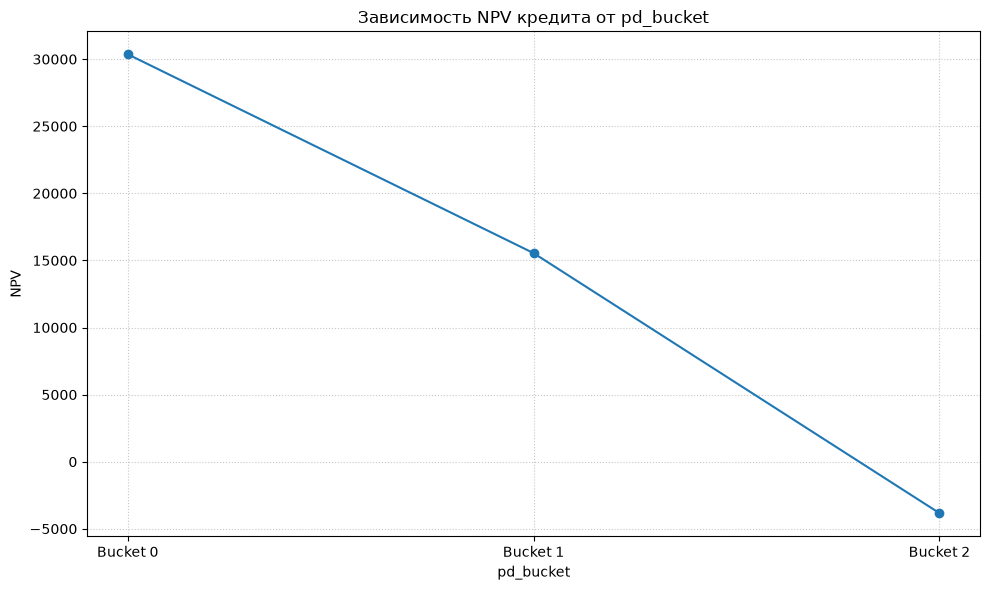

In [115]:
plt.figure(figsize=(10, 6))

x_labels = [f"Bucket {k}" for k in sorted(npv_results.keys())]
y_vals = [npv_results[k] for k in sorted(npv_results.keys())]

plt.plot(x_labels, y_vals, marker="o")

plt.title(
    "Зависимость NPV кредита от pd_bucket",
)

plt.xlabel("pd_bucket")
plt.ylabel("NPV")
plt.grid(True, linestyle=":", alpha=0.7)
plt.tight_layout()
plt.show()